In [1]:
import pandas as pd
import numpy as np
import scipy
from sklearn.decomposition import NMF
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns


import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, cophenet
from scipy.optimize import linear_sum_assignment

# set random seed here for reproducibilility
import random
random_seed = 42
np.random.seed(random_seed)
random.seed(random_seed)

## Reading data

In [26]:
# NMR spectra
d_sub = pd.read_csv("./nmr-raw/NMR_sub.csv", index_col = 0)
d_sub = d_sub.clip(lower = 0.0001)
d_sub

,X9.48,X9.44,X9.4,X9.36,X9.32,X9.28,X9.24000001,X9.20000001,X9.16000001,X9.12000001,...,X0.88000019,X0.84000019,X0.80000019,X0.7600002,X0.7200002,X0.6800002,X0.6400002,X0.6000002,X0.5600002,X0.5200002
Sample,,,,,,,,,,,,,,,,,,,,,
6_r1_t1,0.004571,0.005354,0.005152,0.004721,0.004785,0.005150,0.004593,0.004982,0.004824,0.004964,...,0.233783,0.049308,0.018225,0.012839,0.010833,0.008160,0.006061,0.005503,0.004908,0.004827
6_r2_t1,0.004967,0.005209,0.004617,0.005035,0.004913,0.004928,0.004755,0.004882,0.004957,0.004677,...,0.217972,0.045988,0.016831,0.011488,0.009404,0.007165,0.005257,0.004566,0.004220,0.004426
6_r3_t1,0.004882,0.004533,0.004561,0.004443,0.004339,0.004917,0.004571,0.004603,0.004509,0.004874,...,0.218883,0.045901,0.016239,0.011163,0.009030,0.006850,0.005184,0.004073,0.003926,0.004032
6_r4_t1,0.005108,0.004823,0.004799,0.004863,0.004819,0.005118,0.004626,0.004586,0.004470,0.004786,...,0.218295,0.046236,0.016416,0.011071,0.008852,0.007111,0.005206,0.004687,0.003833,0.003795
105_r1_t1,0.005226,0.005190,0.005103,0.005049,0.005156,0.005070,0.004968,0.004848,0.004853,0.005298,...,0.208800,0.044582,0.015935,0.011147,0.008993,0.007026,0.005433,0.004698,0.004340,0.004488
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1977_evo_r4_ep,0.004495,0.003856,0.003632,0.004450,0.004283,0.004012,0.004282,0.004290,0.003999,0.004069,...,0.171109,0.041422,0.013136,0.008501,0.005997,0.004594,0.004005,0.003810,0.003271,0.003282
5 % KB_r1_ep,0.004558,0.004676,0.003871,0.004322,0.004348,0.004597,0.004369,0.004360,0.004829,0.004463,...,0.164130,0.038749,0.012026,0.007550,0.005562,0.004375,0.004245,0.003236,0.002895,0.003277
5 % KB_r2_ep,0.004494,0.004676,0.004439,0.004877,0.004682,0.004346,0.004571,0.004627,0.004963,0.004616,...,0.178423,0.042771,0.013112,0.008765,0.006868,0.005218,0.004411,0.004117,0.003809,0.003394


In [27]:
# Sample metadata
d_sub_samples = pd.read_csv("./nmr-raw/NMR_sample_sub.csv", index_col= 0)
d_sub_samples.index = d_sub_samples["Label"]
d_sub_samples

,Community type,Community,Replicate,Time point,Label,Control meta
Label,,,,,,
6_r1_t1,Single,6,1,1,6_r1_t1,0
6_r2_t1,Single,6,2,1,6_r2_t1,0
6_r3_t1,Single,6,3,1,6_r3_t1,0
6_r4_t1,Single,6,4,1,6_r4_t1,0
105_r1_t1,Single,105,1,1,105_r1_t1,0
...,...,...,...,...,...,...
1977_evo_r4_ep,Single,1977_evo,4,Endpoint,1977_evo_r4_ep,0
5 % KB_r1_ep,Control,5 % KB,1,Endpoint,5 % KB_r1_ep,0
5 % KB_r2_ep,Control,5 % KB,2,Endpoint,5 % KB_r2_ep,0



## 1) Testing for optimal number of signatures between range [2, 20]

In [140]:
def train(dataset, n_sig):
    """
    produces matrixes W and H from simulated data and fixed number of signatures
    """
    model = NMF(n_components = n_sig, init='random', random_state=None, max_iter = 4000)
    W = model.fit_transform(dataset.T)
    H = model.components_
    L = model.reconstruction_err_
    
    return W, H, L

def plot_nsig_analysis(original, rep, l, match, ax, min_signatures = 2, original_known = True):
    from matplotlib.offsetbox import AnchoredOffsetbox, TextArea, HPacker, VPacker
    
    """
    Plots the result analysis metrics for estimated dataset given by estimate_n_signatures()
    """
    x_max = min_signatures + len(rep)
    ax.plot(np.arange(min_signatures, x_max), rep, color = "red")
    ax.plot(np.arange(min_signatures, x_max), rep, "ro")
    
    ax.plot(np.arange(min_signatures, x_max), match, "green")
    ax.plot(np.arange(min_signatures, x_max), match, "go")
    ax.set_xlim(min_signatures-1, x_max)
    ax.set_xlabel("")
    
    # fancy ylabel with colors
    ybox1 = TextArea("Reproducibility ", textprops=dict(color="r", size=10,rotation=90,ha='left',va='bottom'))
    ybox2 = TextArea("and ",     textprops=dict(color="k", size=10,rotation=90,ha='left',va='bottom'))
    ybox3 = TextArea("Dissimilarity", textprops=dict(color="g", size=10,rotation=90,ha='left',va='bottom'))
    ybox = VPacker(children=[ybox1, ybox2, ybox3],align="bottom", pad=0, sep=5)
    anchored_ybox = AnchoredOffsetbox(loc=7, child=ybox, pad=0., frameon=False, bbox_to_anchor=(-0.08, 0.5), 
                                  bbox_transform=ax.transAxes, borderpad=0.)
    ax.add_artist(anchored_ybox)
    #ax.set_ylabel("Reproducibility", color = "red")
    ax.set_ylabel(None)
    
    #ax.tick_params(axis='y', colors='red')
    
    ax2 = ax.twinx()
    ax2.plot(np.arange(min_signatures, x_max), l, color = "blue")
    ax2.plot(np.arange(min_signatures, x_max), l, "bo")
    ax2.set_ylabel('Loss (MSE/frobenius)', color = "blue")
    ax2.tick_params(axis='y', colors='blue')
    ax2.grid(visible=False)

    if original_known:
        ax.axvline(x=original.shape[0], ymin=0, color = "gray", linestyle = "--")
        ax.set_xlabel("Number of signatures", fontsize = 13)
        ax.set_title('Diagnostics for optimal number of signatures')
        #ax.set_ylabel("Reproducibility", color = "red")
        ax2.set_ylabel('Loss (MSE/frobenius)', color = "blue")


def estimate_n_signatures(dataset, n_sim = 20, min_signatures = 2, max_signatures = 10, return_avg_signatures = True):
    """
    Combines results for calculate-function for different number of n_estimates. Call this function to get stats and average signatures
    for each fixed n in 2...max_signatures
    """
    loss = []
    reproducibility = []
    signatures = []
    match = np.zeros((max_signatures - min_signatures + 1, 2))

    for sigs in range(min_signatures, max_signatures + 1): 
        if sigs%4 == 0:
            print(f"Calculating K={sigs}:")
        if return_avg_signatures:
            l, rep, sig, m = calculate(dataset, n_sim, sigs, return_avg_signatures = True)
        else:
            l, rep, sig, m = calculate(dataset, n_sim, sigs, return_avg_signatures = False)
            
        loss.append(l)
        reproducibility.append(rep)
        signatures.append(sig)
        match[(sigs - min_signatures), :] = m
    
    return np.array(loss), np.array(reproducibility), signatures, match
    
        

def calculate(dataset, n_sim, n_sigs, return_avg_signatures = True):
    """
    Given a dataset and fixed number of signatures, calculates analysis metrics for estimating the optimal number of mutational signatures. 
    Currently returns tuple of (average Silhouette, average Reconstruction loss and the average (or best) of inferred n signatures)
    """
    losses = []

    # train NMF 2 times the numer of simulations (n_sim) spesified, calculate matrics by 50% best runs
    all_signatures = np.zeros([n_sim*2, n_sigs, dataset.shape[1]])
    for sim in range(n_sim*2):
        W, H, Loss = train(dataset, n_sigs)
        losses.append(Loss)
        all_signatures[sim] = W.T

    losses = np.array(losses)
    keep = np.argsort(losses)[0:n_sim] # keep indices with lowest losses

    #return losses, keep

    all_signatures = all_signatures[keep]
    losses = losses[keep]
    Loss = np.mean(losses) # average loss is the first performance metric
    

    temp = all_signatures[np.argmin(losses), :, :]
    all_signatures[np.argmin(losses), :, :] = all_signatures[0, :, :]
    all_signatures[0, :, :] = temp

    # second best match metrics
    matches = np.sort(cosine_similarity(all_signatures[0]), axis = 1)[:, -2]
    #match_best_fit = matches.mean() # average of all sigs
    match_best_fit = np.sort(matches)[-1] # only most similar match
    
    match_avg = []
    for sigs in all_signatures:
        matches = np.sort(cosine_similarity(sigs), axis = 1)[:, -2]
        #match_best_fit = matches.mean() # average of all sigs
        match_avg.append(np.sort(matches)[-1]) # only most similar match
        
        #match_avg.append(np.sort(cosine_similarity(sigs), axis = 1)[:, -2].mean())
    
    match = [match_best_fit, np.array(match_avg).mean()]
    
    # Use the first iteration's signatures to find best matches from latter ones
    for i in range(1, n_sim):
        sim = cosine_similarity(all_signatures[0], all_signatures[i])
        match_permutation = linear_sum_assignment(sim, maximize = True)[1] # Hungarian algorithm to find best matches
        all_signatures[i] = all_signatures[i, match_permutation, :]



    l = np.zeros([n_sigs * n_sim, dataset.shape[1]])
    for i in range(n_sigs):
        l[i * n_sim : i * n_sim + n_sim, :] = all_signatures[:, i, :]

    labels = np.repeat(np.arange(n_sigs), n_sim)
    sil_score = silhouette_score(l, labels, metric = "cosine")
 
    # return average signatures of simulations
    if return_avg_signatures:
        # Taking average of signature elements along signatures can to me intuitively be thought as an "average" of that signature
        avg_sig = np.mean(all_signatures, axis = 0)
        avg_sig = np.apply_along_axis(lambda x: x/sum(x), axis = 1, arr = avg_sig) # let's again keep the signatures scaled
        avg = pd.DataFrame(avg_sig, index = ["inferred_Signature" + str(i+1) for i in range(n_sigs)], columns = None)
        best = pd.DataFrame(all_signatures[np.argmin(losses)], index = ["inferred_Signature" + str(i+1) for i in range(n_sigs)], columns = None)
        return Loss, sil_score, best, match
    
    # else, return signature with lowest reconstruction loss
    return Loss, sil_score, temp, match

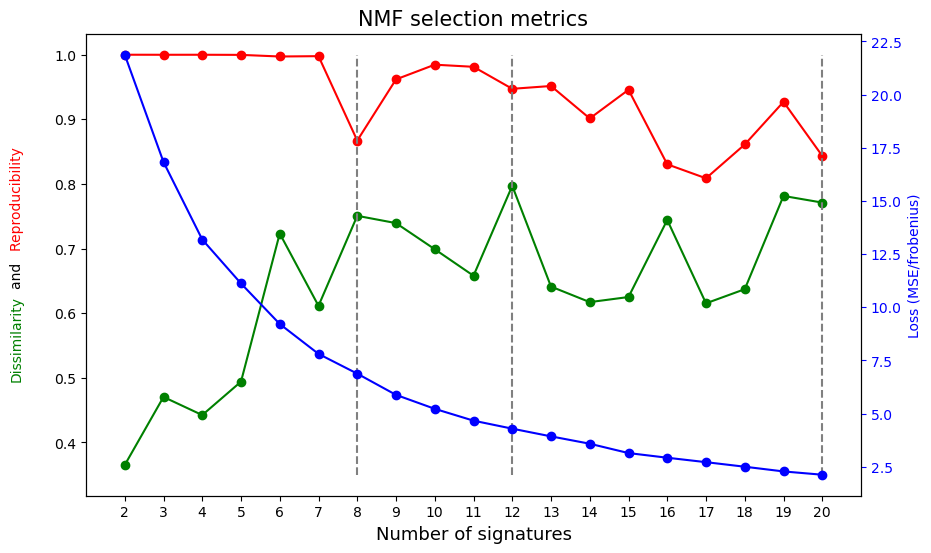

In [64]:
# reconstruction by d_sub
fig, ax = plt.subplots(figsize = (10, 6))
#l, rep, signatures, match = estimate_n_signatures(d_sub, n_sim = 50, min_signatures=2, max_signatures = 20, return_avg_signatures=False)    
plot_nsig_analysis(d_sub, rep = rep, match = match[:, 0], l = l, ax = ax, original_known = True)
ax.set_xticks(range(2, 21))
ax.set_title(f"NMF selection metrics", fontsize = 15)
ax.vlines([8, 12, 20], 0.35, 1, color = "gray", linestyles = "dashed")

# Uncomment to save
#fig.savefig("./figures/k_estimate_metrics.png", bbox_inches='tight', dpi = 300)

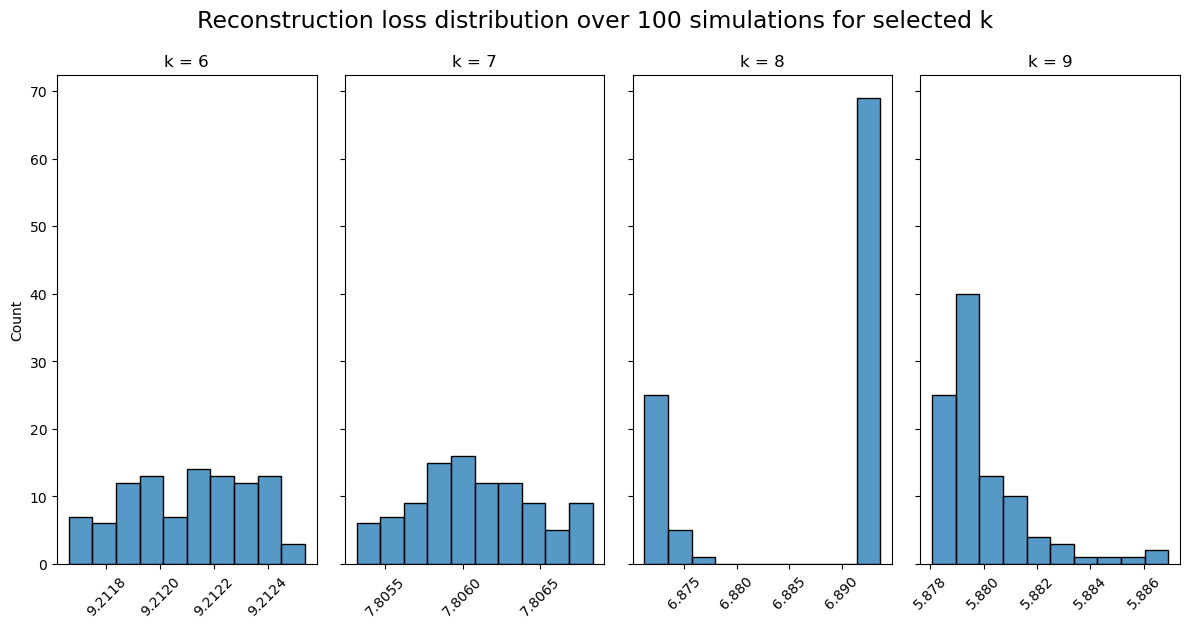

In [138]:
fig_hist, axs_hist = plt.subplots(figsize = (12,6), ncols=4, sharey = True)
for i in range(4):
    losses = []
    for sim in range(100):
        W, H, Loss = train(d_sub, i+6)
        losses.append(Loss)
    sns.histplot(losses, bins = 10, ax = axs_hist[i])
    axs_hist[i].set_title(f"k = {i+6}")
    axs_hist[i].tick_params(axis='x', labelrotation=45)

fig_hist.tight_layout()
fig_hist.suptitle("Reconstruction loss distribution over 100 simulations for selected k", y = 1.05, size = 17);

# uncomment to save
#fig_hist.savefig("./figures/k_estimate_losses_histogram.png", dpi = 300)
        

## 2) Getting the final selected NMF decompositions

In [21]:
def find_best_nmr(dataset, n_sim = 10, n_sigs = 5):
    """
    trains NMF n_sim times, returns best decomposition based on lowest reconstruction loss. Other metrics as well, such as loss histograms etc.?
    """
    losses = []
    min_loss = np.inf

    # train NMF 2 times the numer of simulations (n_sim) spesified, calculate matrics by 50% best runs
    all_signatures = np.zeros([n_sim, n_sigs, dataset.shape[1]])
    for sim in range(n_sim):
        nmf_m = NMF(n_components = n_sigs, random_state = 42+sim, max_iter=4000, init = "random", beta_loss="frobenius", solver = "mu")
        H = nmf_m.fit_transform(dataset)
        W = nmf_m.components_
        l = nmf_m.reconstruction_err_

        if l < min_loss:
            #print(f"Current i: {sim}, min loss: {l}")
            H_min = H
            W_min = W
            min_loss = l
        losses.append(l)

    return H_min, W_min, np.array(losses)

def scale_and_shuffle_nmr(H, W):
    """
    input:
    H: sample activities from NMR fit (samples x n_signatures)
    W: feature signatures from NMR fit (n_signatures * features)

    output (scales: corresponding signatures and activities so that signatures add up to 1):
    H_scaled: scaled H
    W_scaled: scaled W
    
    """
    H_temp = H
    W_temp = W

    # scaling so that signatures sum up to 1:
    scaling_factors = W_temp.sum(axis = 1)
    H_temp = H_temp * scaling_factors
    W_temp = (W.T / scaling_factors).T
    
    # permuting columns based on mean signature activities in controls
    H_control = H_temp[control_mask_sub, :] # check if 5 % KB is included and if relevant in ordering
    permutation = (scipy.stats.rankdata(-H_control.mean(axis = 0)) - 1).astype(int)
    idx = np.empty_like(permutation)
    idx[permutation] = np.arange(len(permutation))

    H_temp = H_temp[:, idx]
    H_temp = pd.DataFrame(H_temp, index = d_sub_samples["Label"], 
                              columns = [f"Sig {i}" for i in range(1, H.shape[1]+1)])
    W_temp = W_temp[idx, :]
    W_temp = pd.DataFrame(W_temp, index = H_temp.columns, 
                              columns = d_sub.columns)

    return H_temp, W_temp

def plot_control_activities(H):
    def set_origin(row):
        if row["Community"] == "Cont6":
            return "Time series"
        elif row["Community type"] == "100 % R2a":
            return "Endpoint"
        else:
            return "Endpoint (5% KB)"
    
    H_temp = H.copy()
    H_temp.index = d_sub_samples.index
    H_controls = H_temp.loc[control_mask_sub, :]
    #pd.DataFrame(H[control_mask, :], index = d_sub_samples.index[control_mask], columns = [f"Sig {i}" for i in range(1, H.shape[1]+1)])
    
    H_controls = H_controls.assign(Origin = d_sub_samples.loc[control_mask_sub, :].apply(set_origin, axis=1))
    
    
    H_m = H_controls.melt(id_vars = "Origin", var_name="Signature", value_name="Activity")
    H_m.columns = ["Control origin", "Signature", "Activity"]
    
    fig, ax = plt.subplots(figsize = (12,5))
    sns.barplot(H_m, x = "Signature", y = "Activity", hue = "Control origin", ax = ax)
    sns.stripplot(H_m, x = "Signature", y = "Activity", hue = "Control origin", dodge = True, jitter = 0.2, 
                  edgecolor = "black", linewidth=0.2, ax = ax, legend=False)
    ax.set_title(f"Signature Activities in control samples (k = {H.shape[1]})", fontsize = 14)

def plot_signatures(W):
    fig, axs = plt.subplots(W.shape[0], figsize = [10, 12])
    for i in range(W.shape[0]):
        axs[i].bar(np.arange(W.shape[1]), W.iloc[i, :], width = 1)
        axs[i].set_title(f"Signature {i+1}")
    fig.suptitle("Overview of signatures", fontsize = 14)
    fig.tight_layout()


def analyze_k_nmf(n_signatures = 8, n_sim = 20):
    print(f"RUNNING NMF WITH K = {n_signatures}")
    print("Fitting NMF:")
    H, W, l = find_best_nmr(d_sub.clip(lower = 0), n_sim = n_sim, n_sigs = n_signatures)
    H1, W1 = scale_and_shuffle_nmr(H, W)
    print("Making evaluation plots:")
    plot_control_activities(H1)
    plot_signatures(W1)

    return H1, W1

### Getting best decompositions for selected number of K's

In [12]:
d_sub_samples = pd.read_csv("./nmr-raw/NMR_sample_sub.csv", index_col= 0)
d_sub_samples.index = d_sub_samples["Label"]
d_sub_samples

,Community type,Community,Replicate,Time point,Label,Control meta
Label,,,,,,
6_r1_t1,Single,6,1,1,6_r1_t1,0
6_r2_t1,Single,6,2,1,6_r2_t1,0
6_r3_t1,Single,6,3,1,6_r3_t1,0
6_r4_t1,Single,6,4,1,6_r4_t1,0
105_r1_t1,Single,105,1,1,105_r1_t1,0
...,...,...,...,...,...,...
1977_evo_r4_ep,Single,1977_evo,4,Endpoint,1977_evo_r4_ep,0
5 % KB_r1_ep,Control,5 % KB,1,Endpoint,5 % KB_r1_ep,0
5 % KB_r2_ep,Control,5 % KB,2,Endpoint,5 % KB_r2_ep,0


In [13]:
# mask for control dample indexes in data
control_mask_sub = ((d_sub_samples["Community type"] == "Control") | (d_sub_samples["Community"] == "Cont")) & \
                (d_sub_samples["Community"] != "5 % KB")              

d_sub_samples.loc[control_mask_sub, :]

,Community type,Community,Replicate,Time point,Label,Control meta
Label,,,,,,
Cont6_r1,Control,Cont6,1,NaN,Cont6_r1,100 % R2A
Cont6_r2,Control,Cont6,2,NaN,Cont6_r2,100 % R2A
Cont6_r3,Control,Cont6,3,NaN,Cont6_r3,100 % R2A
Cont6_r4,Control,Cont6,4,NaN,Cont6_r4,100 % R2A
Cont_r1_ep,100 % R2a,Cont,1,Endpoint,Cont_r1_ep,0
Cont_r2_ep,100 % R2a,Cont,2,Endpoint,Cont_r2_ep,0
Cont_r3_ep,100 % R2a,Cont,3,Endpoint,Cont_r3_ep,0
Cont_r4_ep,100 % R2a,Cont,4,Endpoint,Cont_r4_ep,0
Cont_r5_ep,100 % R2a,Cont,5,Endpoint,Cont_r5_ep,0


RUNNING NMF WITH K = 8
Fitting NMF:
Making evaluation plots:


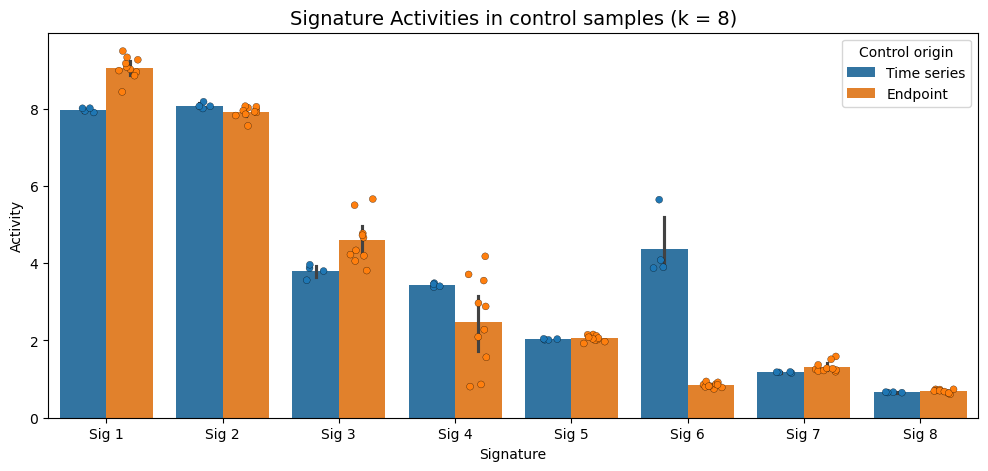

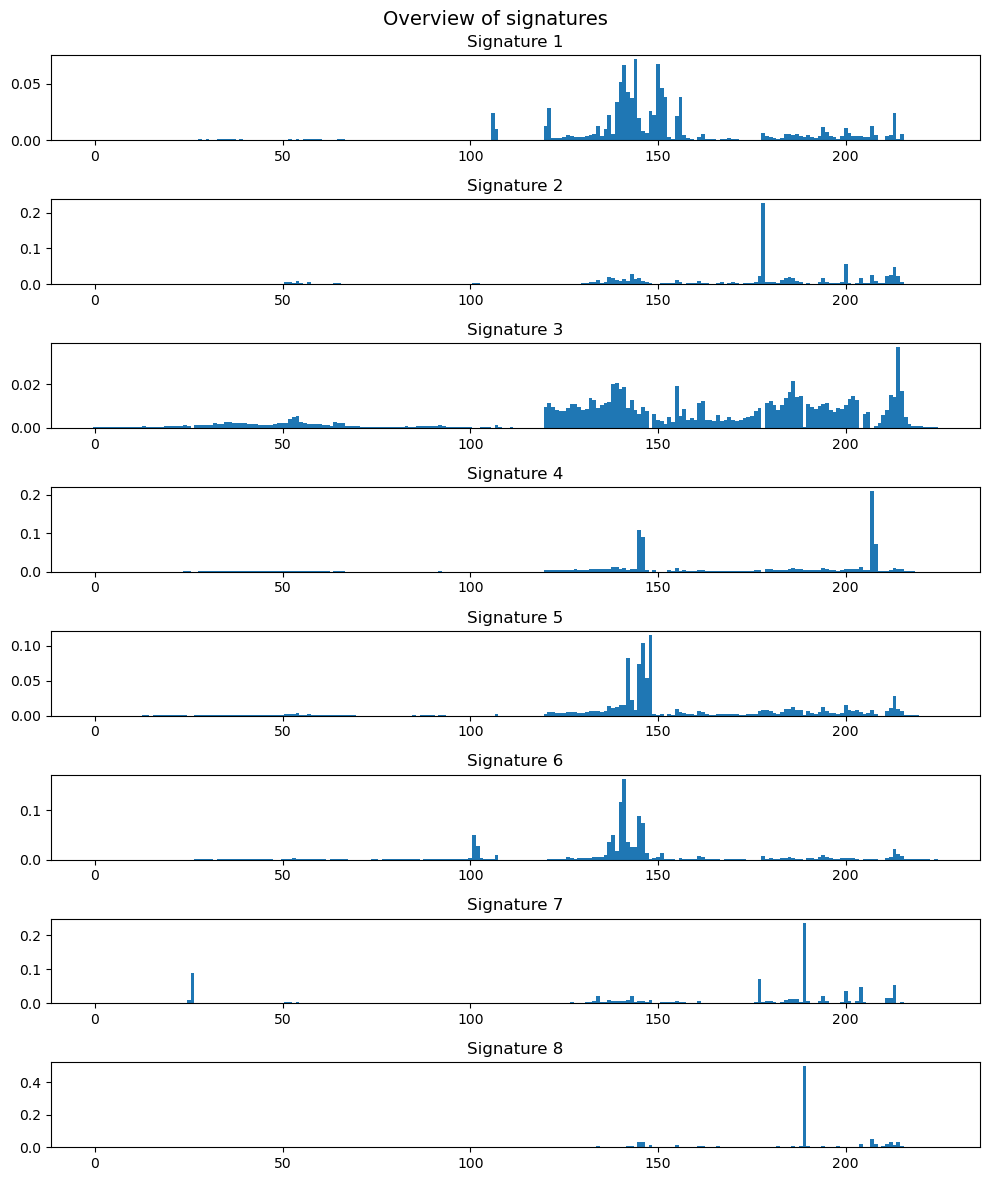

In [23]:
H_8, W_8 = analyze_k_nmf(n_signatures=8, n_sim = 100)

RUNNING NMF WITH K = 12
Fitting NMF:
Making evaluation plots:


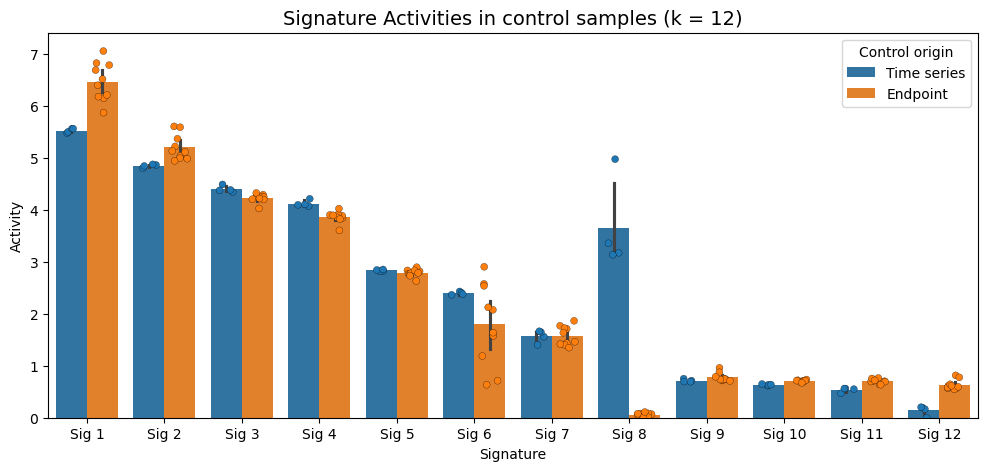

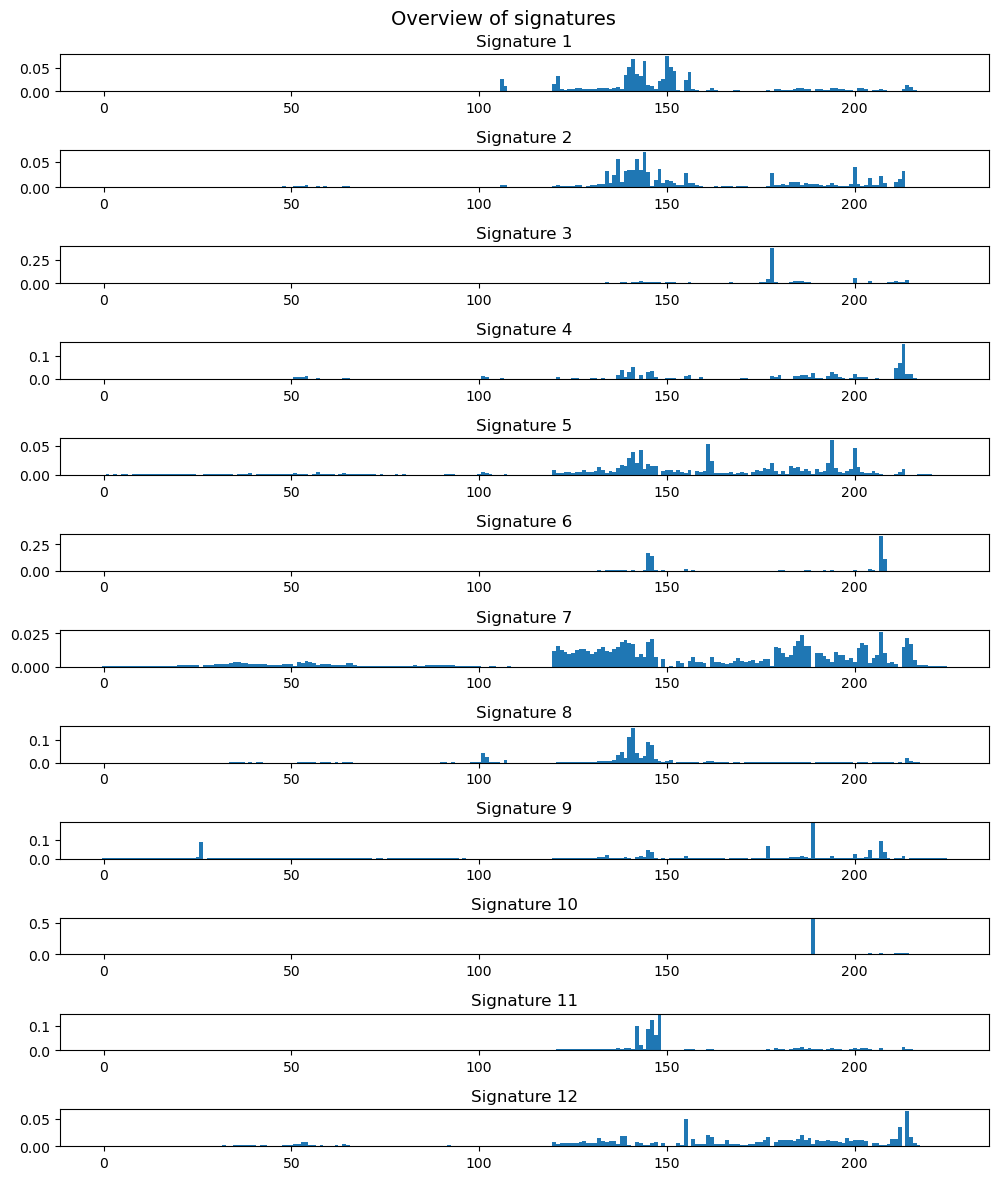

In [24]:
H_12, W_12 = analyze_k_nmf(n_signatures=12, n_sim = 100)

RUNNING NMF WITH K = 20
Fitting NMF:
Making evaluation plots:


/var/folders/13/ymljd8x54c30ykslv4p35d1c0000gn/T/ipykernel_67065/2432487682.py:91: UserWarning: Tight layout not applied. tight_layout cannot make axes height small enough to accommodate all axes decorations.
  fig.tight_layout()


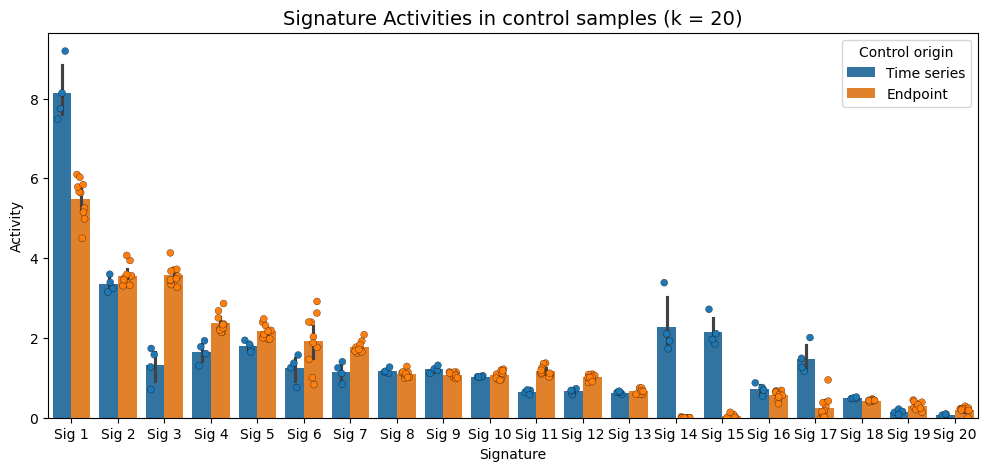

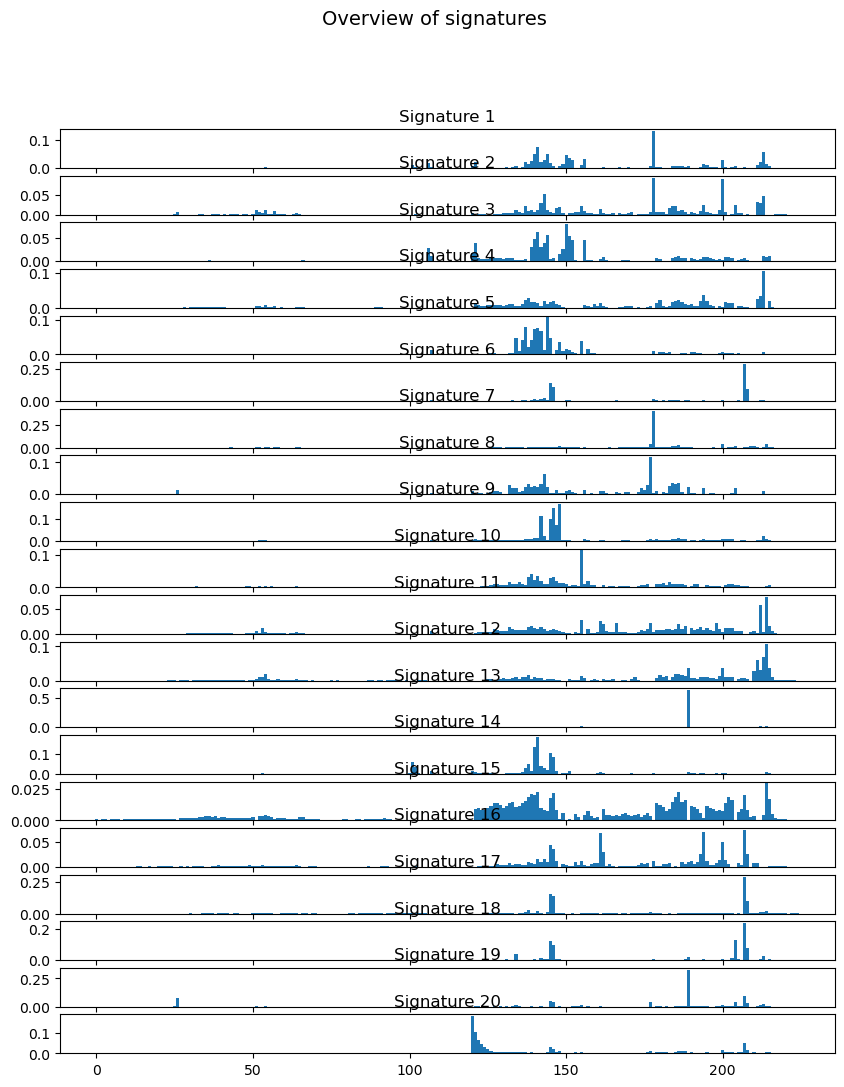

In [25]:
H_20, W_20 = analyze_k_nmf(n_signatures=20, n_sim = 100)

In [45]:
# saving signatures
safe_NMF = False # change to True to save

if safe_NMF:
    W_8.T.to_csv("./nmf_signatures/nmr_signatures_8.csv")
    W_12.T.to_csv("./nmf_signatures/nmr_signatures_12.csv")
    W_20.T.to_csv("./nmf_signatures/nmr_signatures_20.csv")
    
    H_8.to_csv("./nmf_signatures/nmr_activities_8.csv")
    H_12.to_csv("./nmf_signatures/nmr_activities_12.csv")
    H_20.to_csv("./nmf_signatures/nmr_activities_20.csv")

In [164]:
Ws = []
for i in range(6, 14+1):
    H_test, W_test, _ = find_best_nmr(d_sub, n_sim = 100, n_sigs = i)
    H_test, W_test = scale_and_shuffle_nmr(H_test, W_test)
    Ws.append(W_test)

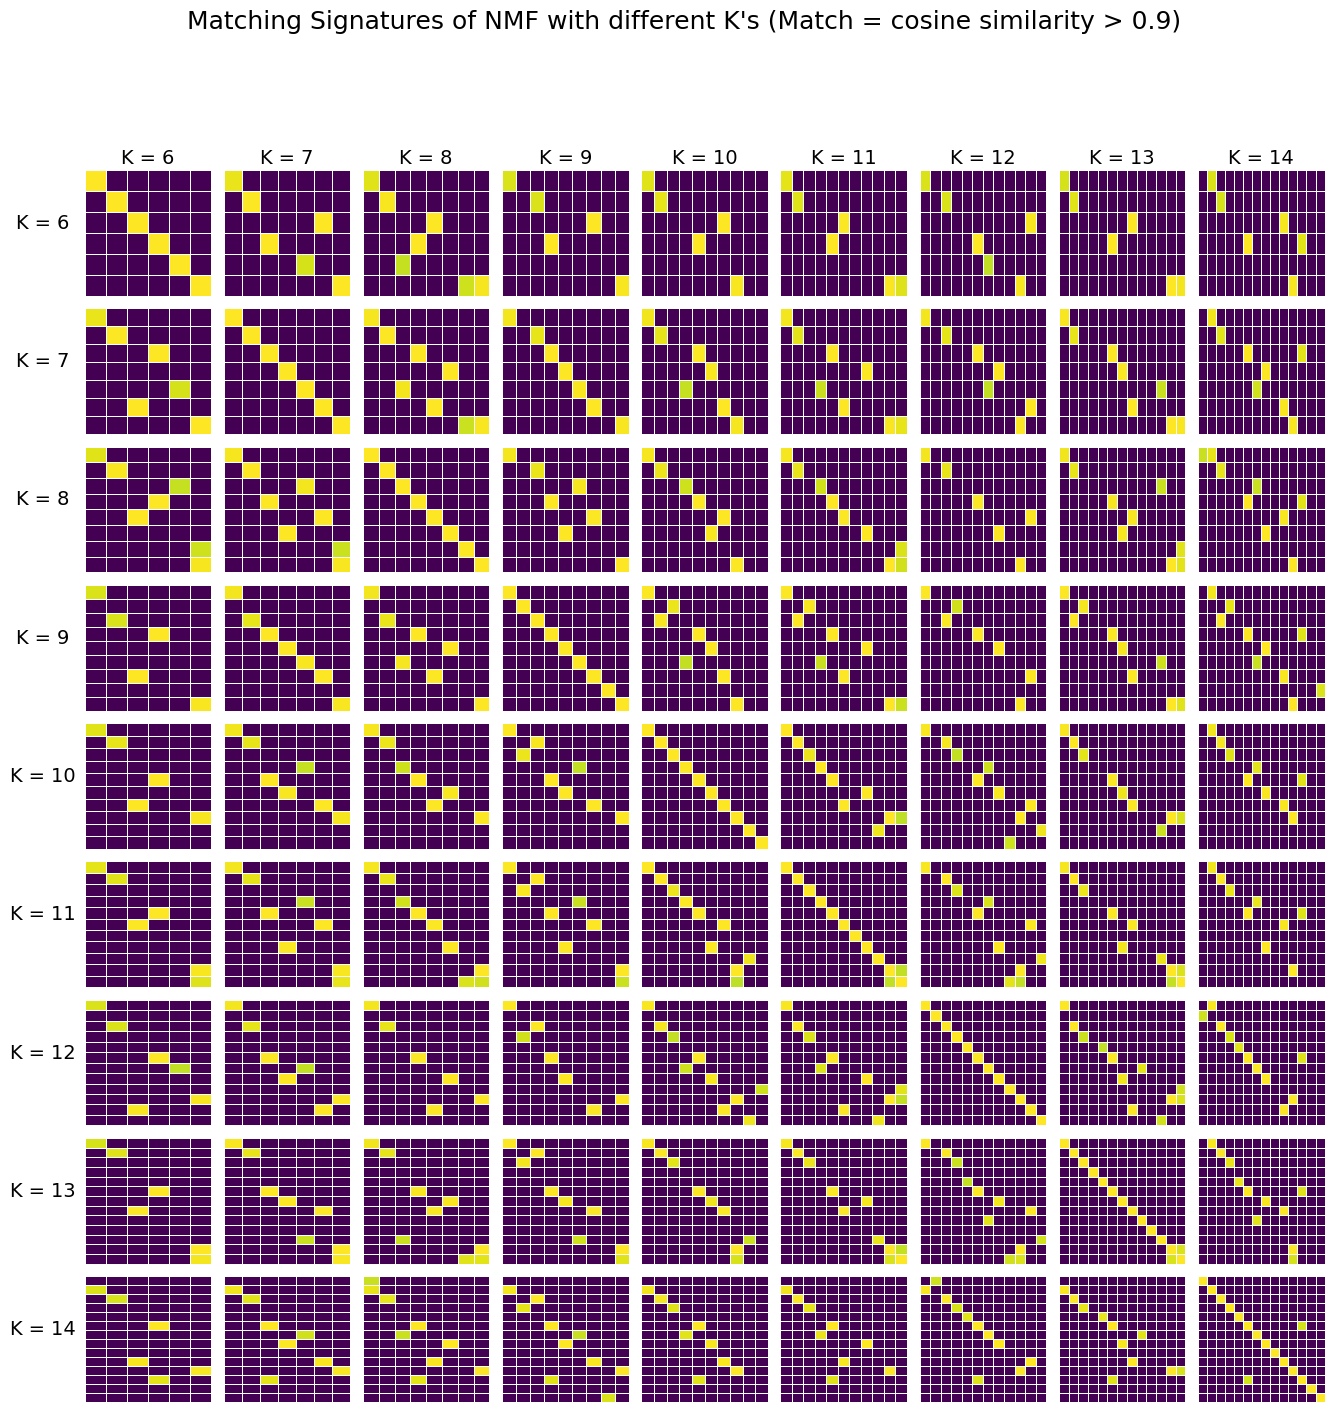

In [166]:
fig, axs = plt.subplots(nrows = len(Ws), ncols = len(Ws), figsize = (16, 16))
fig.subplots_adjust(hspace = 0.1, wspace = 0.1)
fig.suptitle(f"Matching Signatures of NMF with different K's (Match = cosine similarity > 0.9)", fontsize=20, y = 0.94)

sig_ns = list(range(6, 14+1))
for row in range(len(Ws)):
    for col in range(len(Ws)):
        sim = cosine_similarity(Ws[row], Ws[col])
        sim[sim < 0.9] = 0
        sns.heatmap(sim, linewidth = 0.5, cmap = 'viridis', xticklabels = False, yticklabels=False,  #add xticklabels and yticklabels?
                     ax = axs[row, col], cbar = False)
        if row == 0:
            axs[row, col].set_xlabel("K = " + str(sig_ns[col]), fontsize=14)
            axs[row, col].xaxis.set_label_position("top")
        if col == 0:
            axs[row, col].set_ylabel("K = " + str(sig_ns[row]), fontsize=14, rotation=0, labelpad = 30)
            #axs[row, col].yaxis.set_label_position("top")

# uncomment to save
#fig.savefig("./figures/k_estimate_matching_signatures.png", dpi = 300)